# Import Environment variables

In [1]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.ipynb

Found bucket: id=rw-migration-aou-rw-f7a4d148, bucketName=rw-migration-aou-rw-f7a4d148
-> Assigned migration variables (ID: rw-migration-aou-rw-f7a4d148)
Found bucket: id=temporary-workspace-bucket, bucketName=temporary-workspace-bucket-wb-perky-cabbage-8342
Found bucket: id=workspace-bucket, bucketName=workspace-bucket-wb-perky-cabbage-8342
✅ Successfully identified latest dataset: wb-silky-artichoke-2408.C2024Q3R9

Variables extracted:
GOOGLE_CLOUD_PROJECT: wb-perky-cabbage-8342
WORKSPACE_BUCKET: gs://workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_TEMP_BUCKET: gs://temporary-workspace-bucket-wb-perky-cabbage-8342
WORKSPACE_CDR: wb-silky-artichoke-2408.C2024Q3R9
bucket_aou_tutorial: NOT FOUND
bucket_id_aou_tutorial: NOT FOUND
bucket_migrated: gs://rw-migration-aou-rw-f7a4d148
bucket_id_migrated: rw-migration-aou-rw-f7a4d148

✅ Saved to /home/jupyter/.bashrc
C2024Q3R9 BQ_DATASET
Multi-trait-GWAS-in-admixed-populations GIT_REPO
dataset_test2 BQ_DATASET
prep_C2024Q3R9 BQ_DATASET
rw-mig

In [2]:
%run /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.ipynb

WORKSPACE_CDR = wb-silky-artichoke-2408.C2024Q3R9
WORKSPACE_BUCKET = gs://workspace-bucket-wb-perky-cabbage-8342
GOOGLE_PROJECT = wb-perky-cabbage-8342
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables_p2.R
Done! 10 variables saved to: /home/jupyter/repos/Multi-trait-GWAS-in-admixed-populations/notebooks/Setting_Env_Variables.sas


# Import library

In [3]:
%load_ext autoreload
%autoreload 2
    
import os
import subprocess
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt

import my_function as mf

# Data's import

## Clinical data

In [4]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_bc_ko_at_inclusion_223k_nb_BC_WITHIN_5Y_GeneticAncestry_biopsy_FamilyHistory_LastSelection.tsv"

df = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

## BCSC v2 Model

In [5]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_test_eur_bcscRisk_recalib.tsv"

df_bcsc = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

## Mammorisk Model

In [6]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_test_eur_Mammorisk_recalib.tsv"

df_mammorisk = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

## PRS 298, 305 et 311 recalibrate

In [7]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "df_test_eur_prs398_305_311_recalib.tsv"

df_prs = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

## Split de la cohorte européenne

In [8]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "train_ids_eur.csv"

train_ids_eur = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

In [9]:
# get the bucket name
my_bucket = os.getenv('WORKSPACE_BUCKET')

name_of_file_in_bucket = "test_ids_eur.csv"

test_ids_eur = pd.read_csv(my_bucket +'/Data/'+ name_of_file_in_bucket, sep=',', low_memory=False)

## Fusion des données

In [10]:
df_merged = pd.merge(
    df_bcsc,
    df_mammorisk[['person_id','score_mammorisk','score_mammorisk_recalib','risk_group']],
    on='person_id',
    how='left'
)

In [11]:
df_merged = pd.merge(
    df_merged,
    df_prs,
    on='person_id',
    how='left'
)

In [12]:
df_merged.columns

Index(['person_id', 'inclusion_date', 'first_breast_cancer_date', 'delay_days',
       'age_at_inclusion', 'has_bc', 'eur_rye', 'eas_rye', 'amr_rye',
       'afr_rye', 'sas_rye', 'mid_rye', 'dominant_origin', 'ancestry_80',
       'biopsy_result', 'age_category', 'race_us_bcsc', 'race_us_bcsc_detail',
       'breast_cancer_family_history_first_degree', 'score_bcscRisk',
       'score_bcscRisk_recalib', 'risk_group_x', 'score_mammorisk',
       'score_mammorisk_recalib', 'risk_group_y', 'prs_298', 'prs_298_z',
       'prs_298_prob_recalib_only', 'PRS-298_risk_group', 'prs_305',
       'prs_305_z', 'prs_305_prob_recalib_only', 'PRS-305_risk_group',
       'prs_311', 'prs_311_z', 'prs_311_prob_recalib_only',
       'PRS-311_risk_group'],
      dtype='object')

In [13]:
df_scores = df_merged[['person_id','has_bc',
                       'score_bcscRisk_recalib','score_mammorisk_recalib',
                       'prs_298','prs_305','prs_311',
                       'prs_298_z','prs_305_z','prs_311_z',
                       'prs_298_prob_recalib_only','prs_305_prob_recalib_only','prs_311_prob_recalib_only']]
df_scores

,person_id,has_bc,score_bcscRisk_recalib,score_mammorisk_recalib,prs_298,prs_305,prs_311,prs_298_z,prs_305_z,prs_311_z,prs_298_prob_recalib_only,prs_305_prob_recalib_only,prs_311_prob_recalib_only
0,1468526,0,0.006925,0.007036,-0.457323,-0.470491,-0.398409,-0.829042,-0.841663,-0.759039,0.004819,0.004781,0.004939
1,5536083,0,0.006925,0.007036,0.004276,0.030908,0.109466,-0.075160,-0.030784,0.058901,0.005941,0.006007,0.006172
2,2400803,0,0.005012,0.004599,-0.054414,-0.086182,-0.019810,-0.171012,-0.220146,-0.149300,0.005785,0.005695,0.005832
3,1238735,0,0.005012,0.004599,0.349699,0.398231,0.380503,0.488983,0.563261,0.495408,0.006946,0.007099,0.006951
4,5970318,0,0.002165,0.002293,1.031532,1.001864,1.128205,1.602550,1.539475,1.699592,0.009452,0.009336,0.009643
...,...,...,...,...,...,...,...,...,...,...,...,...,...
55183,4386725,0,0.003104,0.004519,0.546978,0.330010,0.389168,0.811178,0.452932,0.509364,0.007594,0.006882,0.006978
55184,2743914,0,0.002165,0.002293,0.760308,0.826940,0.929336,1.159588,1.256583,1.379311,0.008363,0.008624,0.008840
55185,1475516,0,0.002165,0.002293,0.045763,0.172695,0.281567,-0.007404,0.198517,0.336070,0.006053,0.006407,0.006656
55186,9915233,0,0.002165,0.002293,0.075946,0.084178,0.147137,0.041891,0.055366,0.119569,0.006137,0.006154,0.006275


# TEST

In [14]:
import numpy as np
import pandas as pd


def combine_clinical_and_prs(
    df_data,
    beta_prs=0.2789,  # Coefficient beta de la régression logistique du PRS-311
    bcsc_col="score_bcscRisk_recalib",
    mammo_col="score_mammorisk_recalib",
    prs_z_col="prs_311_z",
):
    """Combine les modèles cliniques (BCSC et Mammorisk) avec le PRS-311

    selon l'approche bayésienne/logistique à effets additifs (Élie Rassy et al.).
    """
    df_out = df_data.copy()

    # Protection contre log(0) ou log(1)
    eps = 1e-7
    p_bcsc = np.clip(df_out[bcsc_col], eps, 1 - eps)
    p_mammo = np.clip(df_out[mammo_col], eps, 1 - eps)

    # 1. Conversion des probabilités cliniques en log-odds (logit)
    logit_bcsc = np.log(p_bcsc / (1 - p_bcsc))
    logit_mammo = np.log(p_mammo / (1 - p_mammo))

    # 2. Addition du composant génétique (beta * PRS_z)
    genetic_component = beta_prs * df_out[prs_z_col]

    logit_bcsc_prs = logit_bcsc + genetic_component
    logit_mammo_prs = logit_mammo + genetic_component

    # 3. Reconversion inverse en probabilités absolues combinées
    df_out["prob_bcsc_prs311"] = 1.0 / (1.0 + np.exp(-logit_bcsc_prs))
    df_out["prob_mammorisk_prs311"] = 1.0 / (1.0 + np.exp(-logit_mammo_prs))

    return df_out

In [15]:
# Application directe sur ton DataFrame df_scores
df_scores = combine_clinical_and_prs(
    df_data=df_scores,
    beta_prs=0.2741,  # Remplace par la valeur exacte de beta de ton PRS-311 si différente
    bcsc_col="score_bcscRisk_recalib",
    mammo_col="score_mammorisk_recalib",
    prs_z_col="prs_311_z",
)

In [16]:
df_scores

,person_id,has_bc,score_bcscRisk_recalib,score_mammorisk_recalib,prs_298,prs_305,prs_311,prs_298_z,prs_305_z,prs_311_z,prs_298_prob_recalib_only,prs_305_prob_recalib_only,prs_311_prob_recalib_only,prob_bcsc_prs311,prob_mammorisk_prs311
0,1468526,0,0.006925,0.007036,-0.457323,-0.470491,-0.398409,-0.829042,-0.841663,-0.759039,0.004819,0.004781,0.004939,0.005632,0.005722
1,5536083,0,0.006925,0.007036,0.004276,0.030908,0.109466,-0.075160,-0.030784,0.058901,0.005941,0.006007,0.006172,0.007037,0.007150
2,2400803,0,0.005012,0.004599,-0.054414,-0.086182,-0.019810,-0.171012,-0.220146,-0.149300,0.005785,0.005695,0.005832,0.004812,0.004415
3,1238735,0,0.005012,0.004599,0.349699,0.398231,0.380503,0.488983,0.563261,0.495408,0.006946,0.007099,0.006951,0.005736,0.005264
4,5970318,0,0.002165,0.002293,1.031532,1.001864,1.128205,1.602550,1.539475,1.699592,0.009452,0.009336,0.009643,0.003445,0.003648
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55183,4386725,0,0.003104,0.004519,0.546978,0.330010,0.389168,0.811178,0.452932,0.509364,0.007594,0.006882,0.006978,0.003567,0.005193
55184,2743914,0,0.002165,0.002293,0.760308,0.826940,0.929336,1.159588,1.256583,1.379311,0.008363,0.008624,0.008840,0.003157,0.003342
55185,1475516,0,0.002165,0.002293,0.045763,0.172695,0.281567,-0.007404,0.198517,0.336070,0.006053,0.006407,0.006656,0.002373,0.002513
55186,9915233,0,0.002165,0.002293,0.075946,0.084178,0.147137,0.041891,0.055366,0.119569,0.006137,0.006154,0.006275,0.002237,0.002369


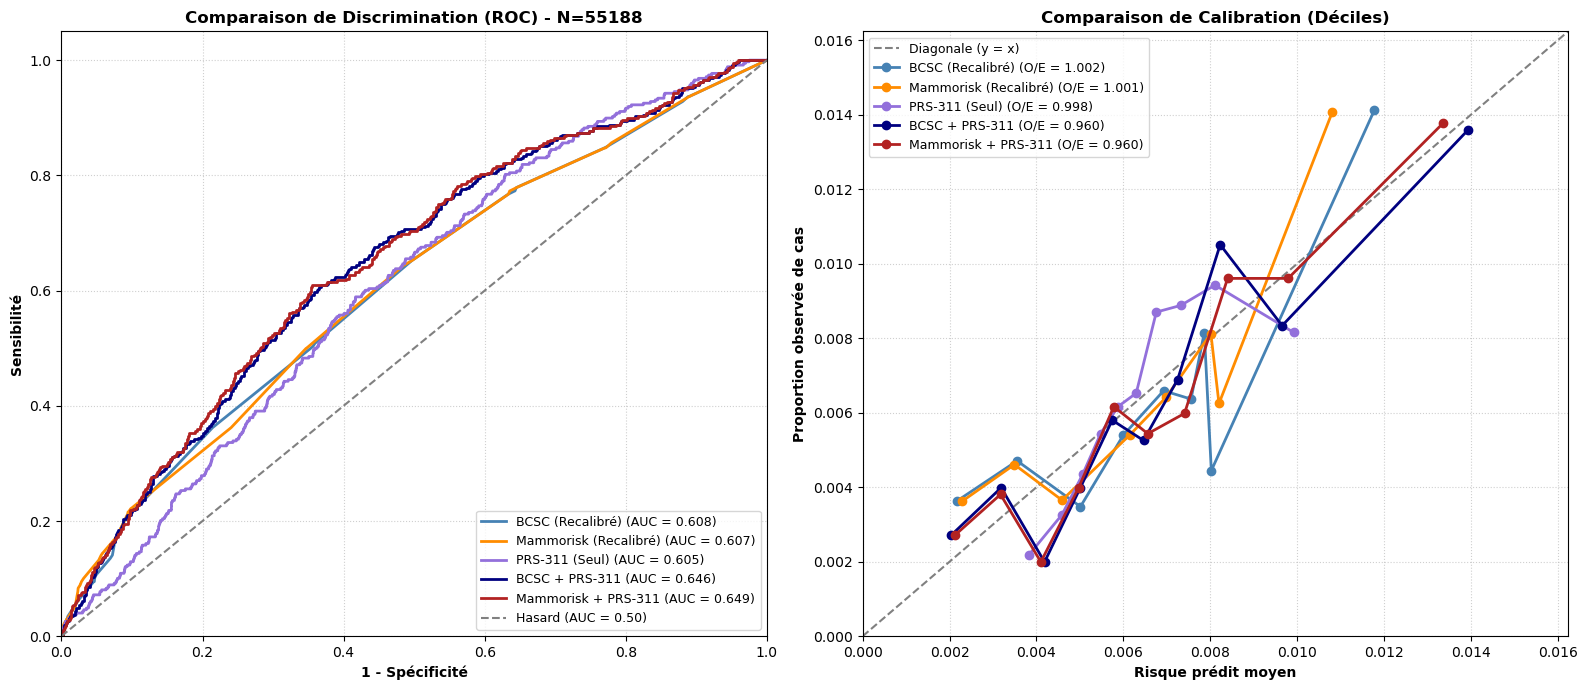

,Modèle,AUC,IC 95% AUC,Cas Observés (O),Cas Attendus (E),Ratio O/E
0,BCSC (Recalibré),0.608,[0.580 - 0.639],348,347.4,1.002
1,Mammorisk (Recalibré),0.607,[0.579 - 0.638],348,347.7,1.001
2,PRS-311 (Seul),0.605,[0.578 - 0.631],348,348.9,0.998
3,BCSC + PRS-311,0.646,[0.620 - 0.676],348,362.5,0.960
4,Mammorisk + PRS-311,0.649,[0.623 - 0.680],348,362.4,0.960


In [17]:
# Évaluation et comparaison des 5 modèles
df_summary = mf.evaluate_and_compare_all_models(
    df_data=df_scores,
    test_ids=test_ids_eur,
)

# Affichage du tableau récapitulatif
display(df_summary)

## Recalibration des modèles combinés

In [19]:
df_scores

,person_id,has_bc,score_bcscRisk_recalib,score_mammorisk_recalib,prs_298,prs_305,prs_311,prs_298_z,prs_305_z,prs_311_z,prs_298_prob_recalib_only,prs_305_prob_recalib_only,prs_311_prob_recalib_only,prob_bcsc_prs311,prob_mammorisk_prs311
0,1468526,0,0.006925,0.007036,-0.457323,-0.470491,-0.398409,-0.829042,-0.841663,-0.759039,0.004819,0.004781,0.004939,0.005632,0.005722
1,5536083,0,0.006925,0.007036,0.004276,0.030908,0.109466,-0.075160,-0.030784,0.058901,0.005941,0.006007,0.006172,0.007037,0.007150
2,2400803,0,0.005012,0.004599,-0.054414,-0.086182,-0.019810,-0.171012,-0.220146,-0.149300,0.005785,0.005695,0.005832,0.004812,0.004415
3,1238735,0,0.005012,0.004599,0.349699,0.398231,0.380503,0.488983,0.563261,0.495408,0.006946,0.007099,0.006951,0.005736,0.005264
4,5970318,0,0.002165,0.002293,1.031532,1.001864,1.128205,1.602550,1.539475,1.699592,0.009452,0.009336,0.009643,0.003445,0.003648
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55183,4386725,0,0.003104,0.004519,0.546978,0.330010,0.389168,0.811178,0.452932,0.509364,0.007594,0.006882,0.006978,0.003567,0.005193
55184,2743914,0,0.002165,0.002293,0.760308,0.826940,0.929336,1.159588,1.256583,1.379311,0.008363,0.008624,0.008840,0.003157,0.003342
55185,1475516,0,0.002165,0.002293,0.045763,0.172695,0.281567,-0.007404,0.198517,0.336070,0.006053,0.006407,0.006656,0.002373,0.002513
55186,9915233,0,0.002165,0.002293,0.075946,0.084178,0.147137,0.041891,0.055366,0.119569,0.006137,0.006154,0.006275,0.002237,0.002369


In [18]:
# 1. Recalibration de l'intercept des modèles combinés
df_scores = mf.recalibrate_combined_models(
    df_data=df_scores,
    train_ids=train_ids_eur,
    test_ids=test_ids_eur,
    combined_cols=["prob_bcsc_prs311", "prob_mammorisk_prs311"],
)

# 2. Évaluation comparative intégrant les versions réétalonnées
models_to_evaluate = {
    "BCSC (Recalibré)": "score_bcscRisk_recalib",
    "Mammorisk (Recalibré)": "score_mammorisk_recalib",
    "PRS-311 (Seul)": "prs_311_prob_recalib_only",
    "BCSC + PRS-311 (Brut)": "prob_bcsc_prs311",
    "BCSC + PRS-311 (Ajusté)": "prob_bcsc_prs311_recalib",
    "Mammorisk + PRS-311 (Brut)": "prob_mammorisk_prs311",
    "Mammorisk + PRS-311 (Ajusté)": "prob_mammorisk_prs311_recalib",
}

df_summary_final = mf.evaluate_and_compare_all_models(
    df_data=df_scores, test_ids=test_ids_eur, models_dict=models_to_evaluate
)

display(df_summary_final)

=== RECALIBRATION DE L'INTERCEPT DES MODÈLES COMBINÉS ===


ValueError: zero-size array to reduction operation maximum which has no identity